<a href="https://colab.research.google.com/github/mchietino/TP-Delito_en_AMBA-Mica-/blob/Mica/Copia_de_TP_Delito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Grupal - Laboratorio de Métodos Cuantitativos
**Universidad de Buenos Aires - Facultad de Ciencias Económicas**  
**Tecnicatura Universitaria en Gestión y Análisis de Datos**  
**Segundo Cuatrimestre 2026**

---

### Integrantes del Grupo:
* **Chietino Luna, Micaela** - Registro: 921785 - Usuario GitHub: `@mchietino`
* **Iandoli, Franco** - Registro: 921507 - Usuario GitHub: `@Franco-Iandoli`
* **Ortiz, Naiara** - Registro: 921844 - Usuario GitHub: `@naiaraortizrodriguez`
* **Peralta, Santiago** - Registro: 921431 - Usuario GitHub: `@SantiagoNPeralta`
* **Turrillo, Bruno** - Registro: 921414 - Usuario GitHub: `@bauhaushm`

---

## 1. Introducción y Pregunta de Investigación

Nuestro grupo se focalizará en la temática del delito y su relación con aspectos sociales que pueden influir en él.

**a) Pregunta de investigación:**

> *"¿Cómo se comparan los patrones delictivos entre los partidos del AMBA, y de qué manera varían el tipo y la frecuencia de los delitos denunciados según las condiciones socioeconómicas y habitacionales al interior de las comunas porteñas?"*

**b) ¿Por qué vale la pena responderla?**
[Completar: qué decisión, fenómeno o problema ilumina. Por ejemplo, que el AMBA concentra gran parte de la población del país y que las políticas de seguridad requieren saber qué delitos predominan en cada territorio y si la brecha entre CABA y el conurbano se achica o se amplía.]

**c) ¿Qué respuesta encontramos?**
[Completar al finalizar el análisis, volviendo a esta celda con los hallazgos concretos.]

### 1.1 Fuente de datos

Utilizamos como fuente principal el Sistema Nacional de Información Criminal (SNIC), del Ministerio de Seguridad de la Nación. La base está disponible en https://www.argentina.gob.ar/seguridad/estadisticascriminales/bases-de-datos y contiene distintos datasets, de los cuales elegimos **"SNIC - Departamentos. Anual. Años 2000-2025"**.

Este dataset cubre todo el país, por lo que lo primero que hacemos es recortarlo al **Área Metropolitana de Buenos Aires (AMBA)**, que es el territorio que nos interesa para responder la pregunta de investigación.

## 2. Carga y exploración inicial de los datos

## 2.1 Importación de librerías

Importamos las librerías que vamos a usar: `pandas` para manipular los archivos, `matplotlib` y `seaborn` para los gráficos, `numpy` para operaciones matemáticas, `colorsys` para definir colores de las barras (convierte colores de HLS a RGB), y `requests` e `io` para descargar el archivo de forma controlada.


In [ ]:
import io
import colorsys
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2 Carga del dataset con fuente de respaldo y recorte al AMBA

En esta celda cargamos el dataset del SNIC con una función que prueba dos fuentes en orden:

1. **URL oficial del SNIC (Ministerio de Seguridad).** Es la fuente primaria, porque garantiza trabajar con la versión original y más actualizada de los datos.
2. **Copia del recorte ya filtrado (AMBA, 2017-2025) del mismo dataset, almacenada en el repositorio de GitHub del grupo.** Si la página oficial no responde (caída del sitio, error de red o tiempo de espera agotado), la función usa esta copia como respaldo.

Elegimos esta estructura por dos motivos. Primero, **reproducibilidad**: el notebook se ejecuta completo sin intervención manual, tanto en nuestras sesiones de Colab como cuando lo revise otra persona, aunque el servidor del SNIC esté temporalmente fuera de servicio. Segundo, **transparencia**: la función informa por pantalla de cuál de las dos fuentes se cargaron los datos, de modo que queda registro de qué versión se utilizó. Usamos la librería `requests` con un límite de tiempo (`timeout`) para evitar que la ejecución quede detenida indefinidamente esperando una respuesta.

Del archivo original pedimos solo seis columnas: "Año", "Provincia", "Departamento", "Tipo de delito", "Cantidad de hechos" y "Tasa de hechos" (cada 100.000 habitantes). Luego aplicamos dos filtros:

- **Período 2017-2025** (los últimos 9 años), para centrar el análisis en el escenario reciente y reducir el tamaño del dataset.
- **Territorio AMBA:** las 15 comunas de la Ciudad Autónoma de Buenos Aires y los 24 partidos del Gran Buenos Aires (conurbano bonaerense). Para evitar confundir partidos con nombres repetidos en otras provincias (como San Martín o Avellaneda), exigimos que coincidan a la vez la provincia y el departamento.

In [ ]:
# 1. Fuentes de datos
URL_SNIC = "https://cloud-snic.minseg.gob.ar/Bases/SNIC/snic-departamentos-anual.xlsx"
URL_REPO = "https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/bauhaushm/snic_amba_2017_2025.csv"
columnas = [0, 2, 4, 6, 7, 12]  # Año, Provincia, Departamento, Tipo de delito, Cantidad de hechos, Tasa

def cargar_snic():
    # Intento 1: URL oficial
    try:
        r = requests.get(URL_SNIC, timeout=30)
        r.raise_for_status()
        print("Datos cargados desde la URL oficial del SNIC.")
        return pd.read_excel(io.BytesIO(r.content), usecols=columnas)
    except Exception as e:
        print(f"No se pudo usar la URL oficial ({type(e).__name__}). Usando copia del repositorio...")
    # Intento 2: copia reducida (AMBA, 2017-2025) en el repositorio
    r = requests.get(URL_REPO, timeout=60)
    r.raise_for_status()
    print("Datos cargados desde la copia reducida en el repositorio de GitHub.")
    return pd.read_csv(io.BytesIO(r.content))

# 2. Cargar el dataset nacional
df = cargar_snic()

# 3. Definir el territorio AMBA
partidos_gba = ["Almirante Brown", "Avellaneda", "Berazategui", "Esteban Echeverría",
    "Ezeiza", "Florencio Varela", "General San Martín", "Hurlingham", "Ituzaingó",
    "José C. Paz", "La Matanza", "Lanús", "Lomas de Zamora", "Malvinas Argentinas",
    "Merlo", "Moreno", "Morón", "Quilmes", "San Fernando", "San Isidro", "San Miguel",
    "Tigre", "Tres de Febrero", "Vicente López"]

es_periodo = df["anio"].between(2017, 2025)
es_caba = df["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires"
es_conurbano = (df["provincia_nombre"] == "Buenos Aires") & (df["departamento_nombre"].isin(partidos_gba))

# 4. Filtrar período y territorio
df_amba = df[es_periodo & (es_caba | es_conurbano)].copy().reset_index(drop=True)

# 5. Verificar el resultado
print(f"El dataset del AMBA contiene {len(df_amba)} filas y {len(df_amba.columns)} columnas.")
print("Años incluidos:", sorted(df_amba["anio"].unique().tolist()))

# 6. Guardar el dataset resultante
df_amba.to_csv("snic_amba_2017_2025.csv", index=False)

Datos cargados desde la URL oficial del SNIC.
El dataset del AMBA contiene 21345 filas y 6 columnas.
Años incluidos: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


### 2.3 Primeras y últimas filas

Mostramos las primeras y últimas filas con `.head()` y `.tail()` para tener una primera impresión del contenido y confirmar que el orden y los valores tienen sentido.

In [ ]:
display(df_amba.head())
display(df_amba.tail())

,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,tasa_hechos
0,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Homicidios dolosos,25,9.870850
1,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Abusos sexuales con acceso carnal (violaciones),14,5.527676
2,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Otros delitos contra la integridad sexual,190,75.018458
3,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Delitos contra el estado civil,0,0.000000
4,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Amenazas,1074,424.051707


,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,tasa_hechos
21340,2025,Buenos Aires,Vicente López,Lesiones dolosas,435,155.000641
21341,2025,Buenos Aires,Vicente López,Lesiones culposas en Accidentes Viales,681,242.656177
21342,2025,Buenos Aires,Vicente López,Lesiones culposas por otros hechos,13,4.632203
21343,2025,Buenos Aires,Vicente López,Otros delitos contra las personas,30,10.689699
21344,2025,Buenos Aires,Vicente López,Delitos contra el honor,0,0.000000


### 2.4 Estructura del dataset

Describimos las dimensiones, las columnas, sus tipos de dato (`.dtypes`) y la cobertura temporal y geográfica, para verificar que cada variable tenga el tipo adecuado (por ejemplo, el año como entero y la tasa como número decimal).

In [ ]:
print("Dimensiones (filas, columnas):", df_amba.shape)
print("\nColumnas y tipos de dato:")
print(df_amba.dtypes)
print("\nCobertura temporal:", df_amba["anio"].min(), "a", df_amba["anio"].max())
print("Comunas y partidos distintos:", df_amba["departamento_nombre"].nunique())
print("Tipos de delito distintos:", df_amba["codigo_delito_snic_nombre"].nunique())

Dimensiones (filas, columnas): (21345, 6)

Columnas y tipos de dato:
anio                           int64
provincia_nombre              object
departamento_nombre           object
codigo_delito_snic_nombre     object
cantidad_hechos                int64
tasa_hechos                  float64
dtype: object

Cobertura temporal: 2017 a 2025
Comunas y partidos distintos: 40
Tipos de delito distintos: 66


### 2.5 Calidad de los datos

Analizamos la presencia de valores nulos (`.isnull().sum()`), filas duplicadas y estadísticas descriptivas (`.describe()`). También calculamos qué proporción de las filas tiene cero hechos, porque en el SNIC un cero puede significar que no hubo casos, y eso condiciona cómo interpretamos las tasas y los promedios.

In [ ]:
print("Valores nulos por columna:")
print(df_amba.isnull().sum())
print("\nFilas duplicadas:", df_amba.duplicated().sum())
print(f"\nProporción de filas con cero hechos: {(df_amba['cantidad_hechos'] == 0).mean():.1%}")
df_amba.describe()

Valores nulos por columna:
anio                           0
provincia_nombre               0
departamento_nombre            0
codigo_delito_snic_nombre      0
cantidad_hechos                0
tasa_hechos                  534
dtype: int64

Filas duplicadas: 0

Proporción de filas con cero hechos: 42.2%


,anio,cantidad_hechos,tasa_hechos
count,21345.000000,21345.000000,20811.000000
mean,2021.170063,207.841368,67.360475
std,2.609329,736.560238,232.586402
min,2017.000000,0.000000,0.000000
25%,2019.000000,0.000000,0.000000
50%,2021.000000,3.000000,1.282462
75%,2023.000000,73.000000,22.706979
max,2025.000000,22881.000000,4053.030001


### 2.6 Diagnóstico de valores nulos en la tasa

Antes de decidir cómo tratar los nulos de `tasa_hechos`, analizamos cuántos hay en el AMBA y cómo se distribuyen por año, por comuna o partido y por cantidad de hechos.

In [ ]:
nulos_tasa = df_amba[df_amba["tasa_hechos"].isna()]
print(f"Nulos en tasa_hechos: {len(nulos_tasa)} ({len(nulos_tasa) / len(df_amba):.2%})")
print("\nPor año:")
print(nulos_tasa.groupby("anio").size())
print("\nPor comuna/partido (top 10):")
print(nulos_tasa.groupby("departamento_nombre").size().sort_values(ascending=False).head(10))
print("\nCantidad de hechos en las filas con tasa nula:")
print(nulos_tasa["cantidad_hechos"].describe())

Nulos en tasa_hechos: 534 (2.50%)

Por año:
anio
2017    56
2018    56
2019    56
2020    56
2021    56
2022    56
2023    66
2024    66
2025    66
dtype: int64

Por comuna/partido (top 10):
departamento_nombre
Departamento sin determinar    534
dtype: int64

Cantidad de hechos en las filas con tasa nula:
count      534.000000
mean       236.765918
std        811.529762
min          0.000000
25%          1.000000
50%          9.500000
75%         96.750000
max      10000.000000
Name: cantidad_hechos, dtype: float64


### 2.7 Exclusión de los hechos sin comuna asignada

Los registros con `departamento_nombre` igual a "Departamento sin determinar" corresponden a hechos que el SNIC no pudo atribuir a una comuna o partido. Representan todos los nulos de `tasa_hechos`, porque sin territorio no hay población de referencia para calcular la tasa. Como nuestra pregunta compara patrones entre comunas y partidos, estos registros no son utilizables. Antes de excluirlos, cuantificamos cuántos hechos representan para declarar el efecto como limitación.

In [ ]:
etiqueta = "Departamento sin determinar"
sd = df_amba[df_amba["departamento_nombre"] == etiqueta]

print("Provincia de origen de las filas sin determinar:")
print(sd["provincia_nombre"].value_counts())

hechos_sd = sd["cantidad_hechos"].sum()
hechos_amba = df_amba["cantidad_hechos"].sum()
caba = df_amba["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires"
hechos_caba = df_amba.loc[caba, "cantidad_hechos"].sum()

print(f"\nHechos sin comuna asignada: {hechos_sd:,.0f}")
print(f"Porcentaje del total AMBA: {hechos_sd / hechos_amba:.2%}")
print(f"Porcentaje del total de CABA: {hechos_sd / hechos_caba:.2%}")

Provincia de origen de las filas sin determinar:
provincia_nombre
Ciudad Autónoma de Buenos Aires    534
Name: count, dtype: int64

Hechos sin comuna asignada: 126,433
Porcentaje del total AMBA: 2.85%
Porcentaje del total de CABA: 7.08%


In [ ]:
df_amba = df_amba[df_amba["departamento_nombre"] != etiqueta].reset_index(drop=True)

print(f"Filas restantes: {len(df_amba)}")
print("Nulos en tasa_hechos:", df_amba["tasa_hechos"].isna().sum())
print("Nulos totales por columna:")
print(df_amba.isnull().sum())

Filas restantes: 20811
Nulos en tasa_hechos: 0
Nulos totales por columna:
anio                         0
provincia_nombre             0
departamento_nombre          0
codigo_delito_snic_nombre    0
cantidad_hechos              0
tasa_hechos                  0
dtype: int64


### 2.8 Verificación del recorte

Comprobamos que el filtro haya capturado las 15 comunas de CABA y los 24 partidos del conurbano. Si algún partido figura como faltante, es probable que el SNIC lo nombre distinto (abreviaturas, tildes, mayúsculas) y haya que ajustar la lista.

In [ ]:
dep_caba = sorted(df_amba.loc[df_amba["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires", "departamento_nombre"].unique())
dep_conurbano = sorted(df_amba.loc[df_amba["provincia_nombre"] == "Buenos Aires", "departamento_nombre"].unique())

print(f"Comunas de CABA encontradas: {len(dep_caba)} (esperadas: 15)")
print(f"Partidos del conurbano encontrados: {len(dep_conurbano)} (esperados: 24)")
print("Partidos faltantes:", sorted(set(partidos_gba) - set(dep_conurbano)))

Comunas de CABA encontradas: 15 (esperadas: 15)
Partidos del conurbano encontrados: 24 (esperados: 24)
Partidos faltantes: []


### 2.9 Diagnóstico de los tipos de delito

El SNIC pasa de 56 a 66 tipos de delito en 2023. Identificamos cuáles son los tipos nuevos y comprobamos que no existan categorías agregadas ("Total") que puedan inflar las sumas. Además comparamos los hechos de los tipos comunes y de los nuevos por año, para evaluar si el cambio de clasificación afecta la comparabilidad de la serie.

In [ ]:
tipos_por_anio = {a: set(g["codigo_delito_snic_nombre"]) for a, g in df_amba.groupby("anio")}
tipos_comunes = set.intersection(*tipos_por_anio.values())
tipos_nuevos = tipos_por_anio[2025] - tipos_comunes

print(f"Tipos presentes en todos los años: {len(tipos_comunes)}")
print(f"Tipos que aparecen desde 2023: {len(tipos_nuevos)}")
for t in sorted(tipos_nuevos):
    print("  -", t)

print("\nTipos que contienen 'total':", [t for t in df_amba['codigo_delito_snic_nombre'].unique() if "total" in t.lower()])

es_comun = df_amba["codigo_delito_snic_nombre"].isin(tipos_comunes)
resumen = pd.DataFrame({
    "hechos_tipos_comunes": df_amba[es_comun].groupby("anio")["cantidad_hechos"].sum(),
    "hechos_tipos_nuevos": df_amba[~es_comun].groupby("anio")["cantidad_hechos"].sum()
}).fillna(0)
resumen

Tipos presentes en todos los años: 56
Tipos que aparecen desde 2023: 10
  - Abuso sexual agravado
  - Abuso sexual simple
  - Acceso ilegal a sistemas informáticos y daños informáticos
  - Ciberdelitos sexuales vinculados a menores
  - Daños (no incluye informáticos)
  - Estafas y defraudaciones (no incluye virtuales) y usura
  - Estafas y defraudaciones asistidas virtualmente
  - Extorsiones
  - Secuestros extorsivos
  - Tentativa de abuso sexual con acceso carnal

Tipos que contienen 'total': []


,hechos_tipos_comunes,hechos_tipos_nuevos
anio,,
2017,414286,0.0
2018,430558,0.0
2019,518968,0.0
2020,401475,0.0
2021,472926,0.0
2022,494481,0.0
2023,477888,48327.0
2024,488345,61343.0
2025,455144,46200.0


### 2.10 Exclusión de los tipos de delito incorporados desde 2023

Para que la serie 2017-2025 sea comparable, nos quedamos solo con los 56 tipos de delito presentes en todos los años y excluimos los 10 que el SNIC incorporó en 2023. De lo contrario, los totales anuales mostrarían un aumento artificial a partir de ese año que reflejaría un cambio de clasificación y no un cambio real en el delito. Cuantificamos cuántos hechos se dejan afuera para declararlo como limitación.

In [ ]:
filas_antes = len(df_amba)
hechos_antes = df_amba["cantidad_hechos"].sum()

df_amba = df_amba[df_amba["codigo_delito_snic_nombre"].isin(tipos_comunes)].reset_index(drop=True)

hechos_despues = df_amba["cantidad_hechos"].sum()
print(f"Filas: {filas_antes} -> {len(df_amba)}")
print(f"Hechos excluidos: {hechos_antes - hechos_despues:,.0f} ({1 - hechos_despues / hechos_antes:.2%} del total 2017-2025)")
print("\nTipos de delito por año:")
print(df_amba.groupby("anio")["codigo_delito_snic_nombre"].nunique())

Filas: 20811 -> 19641
Hechos excluidos: 155,870 (3.62% del total 2017-2025)

Tipos de delito por año:
anio
2017    56
2018    56
2019    56
2020    56
2021    56
2022    56
2023    56
2024    56
2025    56
Name: codigo_delito_snic_nombre, dtype: int64


### 2.11 Visualización del dataframe del AMBA

Visualizamos el dataframe resultante. Cada fila representa la cantidad de hechos y la tasa por 100.000 habitantes de un tipo de delito, en una comuna o partido y un año determinados.

In [ ]:
df_amba

,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,tasa_hechos
0,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Homicidios dolosos,25,9.870850
1,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Abusos sexuales con acceso carnal (violaciones),14,5.527676
2,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Otros delitos contra la integridad sexual,190,75.018458
3,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Delitos contra el estado civil,0,0.000000
4,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Amenazas,1074,424.051707
...,...,...,...,...,...,...
19636,2025,Buenos Aires,Vicente López,Lesiones dolosas,435,155.000641
19637,2025,Buenos Aires,Vicente López,Lesiones culposas en Accidentes Viales,681,242.656177
19638,2025,Buenos Aires,Vicente López,Lesiones culposas por otros hechos,13,4.632203
19639,2025,Buenos Aires,Vicente López,Otros delitos contra las personas,30,10.689699


### 2.12 Hallazgos de la exploración

- **Estructura:** el recorte del AMBA, para 2017-2025, tenía 21.345 filas y 6 columnas, con los tipos adecuados (año y cantidad de hechos como enteros, tasa como decimal). Tras la exclusión de los hechos sin comuna asignada y de los tipos de delito incorporados desde 2023, quedan 19.641 filas, correspondientes a 15 comunas de CABA y 24 partidos del conurbano.
- **Valores nulos:** el único nulo estaba en `tasa_hechos` (534 casos, 2,50%), todos en registros con "Departamento sin determinar", es decir, hechos que el SNIC no pudo atribuir a una comuna y para los que no existe población de referencia. Los excluimos, ya que no son utilizables para comparar territorios. Corresponden íntegramente a CABA y representan el 2,85% de los hechos del AMBA y el 7,08% de los de CABA, subestimados en torno al 7% y las comparaciones se hacen a nivel de comuna y partido. Tras la exclusión no quedan nulos en ninguna columna.
- **Cobertura de tipos de delito:** el SNIC pasa de 56 a 66 tipos desde 2023 (se incorporan, entre otros, ciberdelitos, extorsiones, secuestros extorsivos y estafas asistidas virtualmente). Esos 10 tipos nuevos representan entre el 9% y el 11% de los hechos de 2023-2025 y generarían un salto artificial en la serie temporal. Para garantizar la comparabilidad entre años, el análisis se restringe a los 56 tipos presentes en todo el período, lo que deja fuera el 3,6% de los hechos del total 2017-2025.
- **Duplicados:** no se encontraron filas duplicadas.
- **Ceros:** antes de las exclusiones, el 42,2% de las filas registraba cero hechos, ya que muchos tipos de delito son poco frecuentes en la mayoría de los territorios. Los conservamos, porque un cero informa que no hubo casos.
- **Estadísticos descriptivos:** antes de las exclusiones, la distribución de `tasa_hechos` era muy asimétrica: la mediana (alrededor de 1,3) era mucho menor que la media (alrededor de 67) y el máximo superaba las 4.000 cada 100.000 habitantes. Por eso priorizaremos totales agregados y comparaciones relativas, y no promedios simples entre tipos de delito.

## 3. Transformaciones y resumen estadístico

### 3.1 Creación de la variable `zona`

Para comparar CABA con el conurbano creamos una columna derivada `zona` que clasifica cada registro según su provincia. Esta variable es la base de todas las comparaciones que siguen.

In [ ]:
df_amba["zona"] = np.where(df_amba["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires", "CABA", "Conurbano")
df_amba["zona"].value_counts()

,count
zona,
Conurbano,12096
CABA,7545


### 3.2 Hechos delictivos totales por zona y año

Agrupamos por zona y año y sumamos la cantidad de hechos para ver el volumen de delitos registrado en CABA y en el conurbano y cómo evolucionó.

In [ ]:
hechos_zona_anio = df_amba.groupby(["anio", "zona"])["cantidad_hechos"].sum().unstack()
hechos_zona_anio

zona,CABA,Conurbano
anio,,
2017,176874,237412
2018,169763,260795
2019,195212,323756
2020,133138,268337
2021,172026,300900
2022,189465,305016
2023,183014,294874
2024,187558,300787
2025,177271,277873


**Interpretación:** el conurbano registra más hechos que CABA en todos los años del período, entre 1,3 y 2,0 veces más (1,3 en 2017, 2,0 en 2020 y 1,6 en 2025). Esto es esperable en parte por su mayor población, por lo que la comparación entre zonas se hace con la tasa (sección 3.3) y no con el volumen.

En la evolución, ambas zonas alcanzan su máximo en 2019 y caen en 2020 (CABA 32%, conurbano 17%), un descenso probablemente asociado a las restricciones a la circulación por la pandemia; la mayor caída de CABA amplía la brecha ese año. Desde 2021 las dos se recuperan y la relación conurbano/CABA se estabiliza en torno a 1,6. Entre 2017 y 2025 los hechos en CABA se mantienen prácticamente iguales (+0,2%), mientras que el conurbano crece 17%, aunque ese aumento se concentra hasta 2019 (+36% respecto de 2017) y luego se modera. En 2025 ambas zonas descienden respecto de 2024 (CABA 5,5%, conurbano 7,6%).

Cabe recordar que son hechos registrados, que dependen de las denuncias, y que los totales de CABA están subestimados un 7% por los hechos sin comuna asignada, lo que no altera el sentido de la comparación.

### 3.3 Tasa total de delitos por comuna y partido

Calculamos la tasa total de cada territorio sumando las tasas de todos los tipos de delito (son categorías excluyentes con la misma población de referencia) y promediándola entre 2017 y 2025. Esto permite ordenar a las 39 unidades por nivel de delito relativo a su población.

In [ ]:
tasa_total = (df_amba.groupby(["zona", "departamento_nombre", "anio"])["tasa_hechos"]
              .sum().reset_index(name="tasa_total"))
ranking = (tasa_total.groupby(["zona", "departamento_nombre"])["tasa_total"]
           .mean().sort_values(ascending=False).round(1))
ranking

zona       departamento_nombre
CABA       Comuna 1               10381.2
           Comuna 3                7499.8
           Comuna 4                6920.6
           Comuna 14               6154.8
           Comuna 9                5959.0
           Comuna 15               5526.9
           Comuna 7                5372.5
           Comuna 2                5266.4
           Comuna 8                4976.5
           Comuna 10               4797.1
           Comuna 5                4756.2
           Comuna 11               4371.7
           Comuna 13               4200.8
           Comuna 12               4082.1
           Comuna 6                4011.6
Conurbano  Morón                   3727.0
           General San Martín      3404.3
           Avellaneda              3315.0
           Ituzaingó               3241.4
           Tres de Febrero         3217.2
           Lanús                   2883.1
           Moreno                  2836.6
           San Isidro              2815.0
           Esteban Echeverría      2734.3
           Quilmes                 2731.3
           Malvinas Argentinas     2683.9
           José C. Paz             2681.1
           Tigre                   2635.2
           Berazategui             2619.6
           Hurlingham              2558.4
           Vicente López           2491.8
           San Miguel              2479.3
           Almirante Brown         2444.0
           Ezeiza                  2441.3
           San Fernando            2407.2
           Merlo                   2365.5
           Lomas de Zamora         2322.4
           La Matanza              2159.4
           Florencio Varela        2011.2
Name: tasa_total, dtype: float64

In [ ]:
print(ranking.head(5))
print(ranking.tail(5))
print("\nPromedio simple por zona:")
print(ranking.groupby("zona").mean().round(1))

zona  departamento_nombre
CABA  Comuna 1               10381.2
      Comuna 3                7499.8
      Comuna 4                6920.6
      Comuna 14               6154.8
      Comuna 9                5959.0
Name: tasa_total, dtype: float64
zona       departamento_nombre
Conurbano  San Fernando           2407.2
           Merlo                  2365.5
           Lomas de Zamora        2322.4
           La Matanza             2159.4
           Florencio Varela       2011.2
Name: tasa_total, dtype: float64

Promedio simple por zona:
zona
CABA         5618.5
Conurbano    2716.9
Name: tasa_total, dtype: float64


**Interpretación:** al ajustar por población, el panorama se invierte respecto del volumen: aunque el conurbano registra más hechos en total, las comunas de CABA tienen tasas sensiblemente más altas. El promedio simple de la tasa total anual es de unos 5.620 hechos cada 100.000 habitantes en CABA y de unos 2.720 en el conurbano, es decir, algo más del doble. La diferencia es sistemática: la comuna con menor tasa (Comuna 6, cerca de 4.010) supera al partido con mayor tasa (Morón, cerca de 3.730).

Dentro de cada zona también hay dispersión. En CABA encabezan el ranking las comunas 1, 3, 4, 14 y 9, con la Comuna 1 muy por encima del resto (más de 10.000, casi el doble del promedio de CABA). En el conurbano, los partidos con menores tasas son Florencio Varela, La Matanza, Lomas de Zamora, Merlo y San Fernando (entre 2.000 y 2.400), mientras que Morón, General San Martín y Avellaneda se ubican en el extremo alto de la zona. La brecha entre el territorio de mayor y menor tasa es de unas 2,6 veces en CABA y de unas 1,9 en el conurbano.

Estos resultados deben leerse con cautela. La tasa usa como denominador la población residente, por lo que tiende a sobreestimarse en comunas céntricas con mucha población flotante, como la Comuna 1. Además, se trata de delitos registrados, que dependen de la propensión a denunciar y esta puede diferir entre territorios. Por último, los promedios son simples (no ponderados por población). La fuerte heterogeneidad entre comunas justifica profundizar, en la segunda parte del trabajo, en la relación entre el delito y las condiciones socioeconómicas dentro de CABA.

## 4. Análisis comparativo de las comunas de CABA según zona

La Ciudad de Buenos Aires registra una tasa promedio anual de 5.618,5 hechos cada 100.000 habitantes (2017-2025), pero esa media oculta una dispersión considerable: la Comuna 1 (10.381,2) casi triplica a la Comuna 6 (4.011,6). Además, el delito no se ordena según el nivel de ingresos: las comunas con mayores tasas (1, 3, 4, 14 y 9) pertenecen a las tres zonas de la Ciudad. Esto sugiere que el delito registrado responde a más de un mecanismo, por lo que conviene analizar cada zona por separado.



In [ ]:
# =============================================================================
# INDICADORES SOCIOECONÓMICOS POR COMUNA (EAH - IDECBA): carga, limpieza y base
# =============================================================================
import glob
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns

# Silencia solo los avisos internos de openpyxl; los de seaborn/pandas siguen visibles
warnings.filterwarnings("ignore", module="openpyxl")
logging.getLogger("openpyxl").setLevel(logging.ERROR)
sns.set_theme(style="whitegrid", context="notebook")

# ---------------------------------------------------------------------------
# 0. PARÁMETROS (editables)
# ---------------------------------------------------------------------------
ANIOS = range(2017, 2026)    # años a procesar (2020 se omite solo: sin datos por comuna)
ANIO_GRAFICO = 2024          # año que se muestra en los gráficos

# Las mismas 3 zonas y colores que en la parte de condiciones territoriales
PERFILES = {"Norte": [2, 11, 12, 13, 14],
            "Centro": [1, 3, 5, 6, 7, 10, 15],
            "Sur": [4, 8, 9]}
ORDEN_PERFILES = ["Norte", "Centro", "Sur"]
PALETA = {"Norte": "#FFB6C1", "Centro": "#66CDAA", "Sur": "#87CEFA"}


# ---------------------------------------------------------------------------
# 1. DETECCIÓN AUTOMÁTICA DE ARCHIVOS
# ---------------------------------------------------------------------------
# Leemos los Excel de la EAH directamente desde el GitHub del grupo
url_datos = "https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/franco-iandoli/Datasets/"
file_ipcf = url_datos + "MT_eah_2417.xlsx"  # Ingreso per cápita familiar
file_emp = url_datos + "MT_eah_0917.xlsx"   # Actividad, empleo, desocupación
file_h04 = url_datos + "H04_co.xlsx"        # Personas por ambiente (hacinamiento)
print(f"✓ Ingresos: {file_ipcf}\n✓ Empleo: {file_emp}\n✓ Vivienda: {file_h04}\n")


# ---------------------------------------------------------------------------
# 2. FUNCIONES DE EXTRACCIÓN
# ---------------------------------------------------------------------------
def filas_comunas(raw, columnas, nombres):
    """Filas de las comunas 1-15 (se identifican por su valor, no por su posición).
    Las hojas de empleo traen bloques Total / Varones / Mujeres: se conserva el primero."""
    num = pd.to_numeric(raw[0], errors="coerce")
    out = raw[num.between(1, 15)].iloc[:, columnas].copy()
    out.columns = nombres
    out = out.apply(pd.to_numeric, errors="coerce")   # '---' (dato suprimido) -> NaN
    return out.drop_duplicates("Comuna", keep="first")


def valor_total(raw, columna):
    """Valor de la fila 'Total' (CABA completa) en la columna indicada."""
    fila = raw[raw[0].astype(str).str.strip() == "Total"].iloc[0]
    return pd.to_numeric(fila[columna], errors="coerce")


def procesar_anio(anio):
    hoja = str(anio)

    # A. Ingreso per cápita familiar (pesos corrientes del año)
    raw = pd.read_excel(file_ipcf, sheet_name=hoja, header=None)
    ipcf = filas_comunas(raw, [0, 1], ["Comuna", "IPCF_Promedio"])
    ipcf_total = valor_total(raw, 1)

    # B. Mercado de trabajo
    raw = pd.read_excel(file_emp, sheet_name=hoja, header=None)
    emp = filas_comunas(raw, [0, 1, 2, 3, 5],
                        ["Comuna", "Tasa_Actividad", "Tasa_Empleo",
                         "Tasa_Desocupacion", "Tasa_Subocupacion"])
    desoc_total = valor_total(raw, 3)

    # C. Hacinamiento: % de hogares con MÁS de 2 personas por ambiente.
    # Se calcula como 100 - (hasta 0,99) - (1 a 1,99). Sumar directamente las categorías
    # "2-3" y "más de 3" subestima el valor, porque el IDECBA suprime ('---') o marca '-'
    # las celdas con pocos casos, y esas quedaban como NaN o como 0.
    raw = pd.read_excel(file_h04, sheet_name=hoja, header=None)
    hac = filas_comunas(raw, [0, 2, 3], ["Comuna", "hasta_0_99", "de_1_a_1_99"])
    hac["Pct_Hacinamiento"] = 100 - hac["hasta_0_99"] - hac["de_1_a_1_99"]

    df = (ipcf.merge(emp, on="Comuna").merge(hac[["Comuna", "Pct_Hacinamiento"]], on="Comuna"))
    if df.empty:
        return df
    df["Comuna"] = df["Comuna"].astype(int)
    df["IPCF_Total_CABA"] = ipcf_total
    # Los pesos de distintos años no son comparables (inflación): índice relativo, CABA = 100
    df["IPCF_Relativo"] = (df["IPCF_Promedio"] / ipcf_total * 100).round(2)   # hasta 2 decimales
    df["Desocupacion_Total_CABA"] = desoc_total
    df["Año"] = anio
    return df


# ---------------------------------------------------------------------------
# 3. EJECUCIÓN Y GUARDADO
# ---------------------------------------------------------------------------
bloques = []
for anio in ANIOS:
    try:
        df_anio = procesar_anio(anio)
    except ValueError:   # la hoja del año no existe en alguno de los archivos
        print(f"⚠️ {anio}: no existe la hoja en alguno de los archivos. Se omite.")
        continue
    if df_anio.empty:
        print(f"⚠️ {anio}: los archivos no traen datos por comuna para ese año. Se omite.")
        continue
    bloques.append(df_anio)
    print(f"✓ Año {anio} procesado correctamente.")

df_socioeconomico_caba = pd.concat(bloques, ignore_index=True)
anio_min, anio_max = df_socioeconomico_caba["Año"].min(), df_socioeconomico_caba["Año"].max()
archivo_salida = f"socioeconomico_caba_{anio_min}_{anio_max}.csv"
df_socioeconomico_caba.to_csv(archivo_salida, index=False)
print(f"\nArchivo '{archivo_salida}' generado con éxito. Filas: {len(df_socioeconomico_caba)}")
nulos = df_socioeconomico_caba.isna().sum()
nulos = nulos[nulos > 0]
print("Valores nulos:", "ninguno" if nulos.empty else nulos.to_dict())

# Vista previa con formato de pesos: se hace sobre una COPIA para no convertir
# la columna numérica en texto (eso es lo que rompía los gráficos).
vista = df_socioeconomico_caba.copy()
vista["IPCF_Promedio"] = vista["IPCF_Promedio"].apply(
    lambda x: f"$ {int(x):,}".replace(",", ".") if pd.notna(x) else "N/D")
print("\nVista previa del dataset consolidado:")
display(vista.head(15))


# ---------------------------------------------------------------------------
# 4. APOYO PARA LOS GRÁFICOS
# ---------------------------------------------------------------------------
def asignar_perfil(c):
    for perfil, comunas in PERFILES.items():
        if c in comunas:
            return perfil
    return "Resto de CABA"


def fmt_pesos(v):
    return "$ " + f"{v:,.0f}".replace(",", ".")


def fmt_pct(v):
    return f"{v:.1f}".replace(".", ",") + " %"


def barras_por_comuna(columna, titulo, xlabel, total_caba, fmt, nota):
    """Barras horizontales ordenadas, coloreadas por perfil, con línea del total CABA."""
    d = df_socioeconomico_caba[df_socioeconomico_caba["Año"] == ANIO_GRAFICO].copy()
    d["Perfil"] = d["Comuna"].apply(asignar_perfil)
    d["Etiqueta"] = "Comuna " + d["Comuna"].astype(str)
    d = d.sort_values(columna, ascending=False).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(10, 7.5))
    sns.barplot(data=d, y="Etiqueta", x=columna, hue="Perfil", hue_order=ORDEN_PERFILES,
                palette=PALETA, dodge=False, order=d["Etiqueta"], ax=ax)
    tope = d[columna].max()
    for i, v in enumerate(d[columna]):                  # valor al final de cada barra
        ax.text(v + tope * 0.012, i, fmt(v), va="center", fontsize=9, zorder=5,
                bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))
    ax.axvline(total_caba, color="black", linestyle="--", linewidth=1.2)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.set_xlim(0, tope * 1.15)
    handles = [Patch(facecolor=PALETA[p], label=p) for p in ORDEN_PERFILES]
    handles.append(Line2D([0], [0], color="black", linestyle="--", linewidth=1.2,
                          label=f"Total CABA: {fmt(total_caba)}"))
    ax.legend(handles=handles, title="Zona", loc="lower right", frameon=True)
    fig.text(0.01, -0.01, nota, fontsize=8.5, color="#555555")
    plt.tight_layout()
    return fig, ax


def total_del_anio(columna_total):
    return df_socioeconomico_caba.loc[df_socioeconomico_caba["Año"] == ANIO_GRAFICO,
                                      columna_total].iloc[0]

✓ Ingresos: https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/franco-iandoli/Datasets/MT_eah_2417.xlsx
✓ Empleo: https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/franco-iandoli/Datasets/MT_eah_0917.xlsx
✓ Vivienda: https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/franco-iandoli/Datasets/H04_co.xlsx

✓ Año 2017 procesado correctamente.
✓ Año 2018 procesado correctamente.
✓ Año 2019 procesado correctamente.
⚠️ 2020: los archivos no traen datos por comuna para ese año. Se omite.
✓ Año 2021 procesado correctamente.
✓ Año 2022 procesado correctamente.
✓ Año 2023 procesado correctamente.
✓ Año 2024 procesado correctamente.
✓ Año 2025 procesado correctamente.

Archivo 'socioeconomico_caba_2017_2025.csv' generado con éxito. Filas: 120
Valores nulos: ninguno

Vista previa del dataset consolidado:


,Comuna,IPCF_Promedio,Tasa_Actividad,Tasa_Empleo,Tasa_Desocupacion,Tasa_Subocupacion,Pct_Hacinamiento,IPCF_Total_CABA,IPCF_Relativo,Desocupacion_Total_CABA,Año
0,1,$ 18.037,63.9,58.6,8.4,10.8,21.0,17939,100.55,7.2,2017
1,2,$ 24.070,63.4,59.2,6.8,4.3,5.9,17939,134.18,7.2,2017
2,3,$ 15.775,67.6,61.8,8.5,10.0,14.2,17939,87.94,7.2,2017
3,4,$ 11.918,60.7,54.2,10.8,10.9,20.7,17939,66.44,7.2,2017
4,5,$ 17.427,64.7,61.2,5.4,8.0,7.0,17939,97.15,7.2,2017
5,6,$ 20.662,67.3,63.6,5.4,9.2,2.8,17939,115.18,7.2,2017
6,7,$ 14.414,60.3,55.8,7.4,10.8,10.9,17939,80.35,7.2,2017
7,8,$ 8.295,54.4,47.0,13.7,12.9,23.1,17939,46.24,7.2,2017
8,9,$ 11.669,56.8,54.2,4.6,13.3,11.5,17939,65.05,7.2,2017
9,10,$ 14.008,63.5,59.0,7.1,15.1,4.6,17939,78.09,7.2,2017


### Ingreso per cápita familiar por comuna

Para ver cómo se distribuye el ingreso en la Ciudad, clasificamos las comunas como un semáforo según su ingreso per cápita familiar (IPCF) de 2024, comparado con el promedio de CABA ($ 785.814):

- 🟢 **Ingresos altos:** 10 % o más por encima del promedio.
- 🟡 **Ingresos medios:** hasta 10 % por encima o por debajo del promedio.
- 🔴 **Ingresos bajos:** 10 % o más por debajo del promedio.

Usamos solo el nivel de ingreso, sin agrupar las comunas por zona.

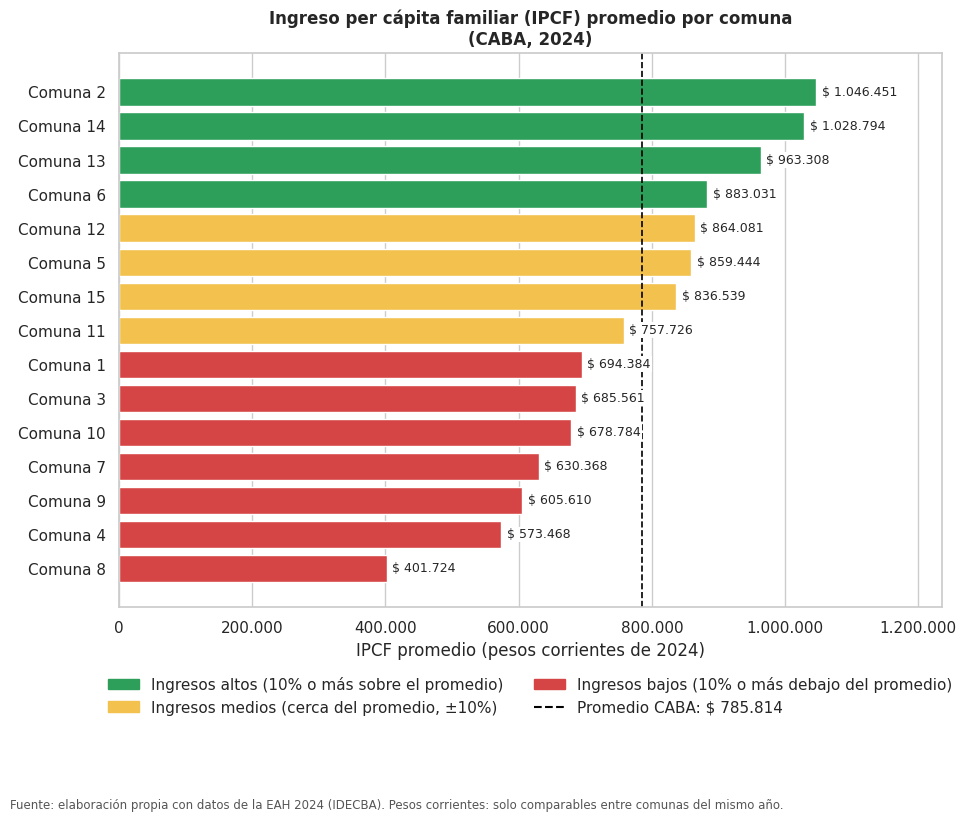

In [ ]:

# 1. Nos quedamos con el año del gráfico y ordenamos de mayor a menor ingreso
d = df_socioeconomico_caba[df_socioeconomico_caba["Año"] == ANIO_GRAFICO].copy()
d = d.sort_values("IPCF_Promedio")
d["Etiqueta"] = "Comuna " + d["Comuna"].astype(str)

# 2. Clasificamos cada comuna comparando su ingreso con el promedio de CABA (= 100)
def semaforo(valor):
    if valor >= 110:
        return "Ingresos altos"
    elif valor >= 90:
        return "Ingresos medios"
    else:
        return "Ingresos bajos"

d["Nivel"] = d["IPCF_Relativo"].apply(semaforo)

# 3. Un color para cada nivel
colores = {"Ingresos altos": "#2E9E5B", "Ingresos medios": "#F2C14E", "Ingresos bajos": "#D64545"}

# 4. Gráfico de barras horizontales
fig, ax = plt.subplots(figsize=(10, 7.5))
barras = ax.barh(d["Etiqueta"], d["IPCF_Promedio"], color=d["Nivel"].map(colores))
ax.bar_label(barras, labels=d["IPCF_Promedio"].apply(fmt_pesos), padding=4, fontsize=9,
             bbox=dict(facecolor="white", edgecolor="none", pad=1))

# Línea punteada con el promedio de CABA
total = total_del_anio("IPCF_Total_CABA")
ax.axvline(total, color="black", linestyle="--", linewidth=1.2)

ax.set_title(f"Ingreso per cápita familiar (IPCF) promedio por comuna\n(CABA, {ANIO_GRAFICO})",
             fontsize=12, fontweight="bold")
ax.set_xlabel(f"IPCF promedio (pesos corrientes de {ANIO_GRAFICO})")
ax.set_xlim(0, d["IPCF_Promedio"].max() * 1.18)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.grid(axis="y", visible=False)

# Leyenda
leyenda = [Patch(color="#2E9E5B", label="Ingresos altos (10% o más sobre el promedio)"),
           Patch(color="#F2C14E", label="Ingresos medios (cerca del promedio, ±10%)"),
           Patch(color="#D64545", label="Ingresos bajos (10% o más debajo del promedio)"),
           Line2D([0], [0], color="black", linestyle="--", label=f"Promedio CABA: {fmt_pesos(total)}")]
ax.legend(handles=leyenda, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)

fig.text(0.01, -0.09, f"Fuente: elaboración propia con datos de la EAH {ANIO_GRAFICO} (IDECBA). "
         "Pesos corrientes: solo comparables entre comunas del mismo año.", fontsize=8.5, color="#555555")
plt.tight_layout()
plt.savefig("grafico_ipcf_por_comuna.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretación:** el ingreso está muy concentrado. Solo 4 comunas superan claramente el promedio (2, 14, 13 y 6), mientras que 7 de las 15 quedan por debajo. La brecha entre extremos es amplia: el IPCF de la Comuna 2 ($ 1.046.451) es 2,6 veces el de la Comuna 8 ($ 401.724), que apenas alcanza la mitad del promedio de la Ciudad.

El grupo rojo no es homogéneo. Las comunas 8, 4 y 9 combinan bajos ingresos con las peores condiciones habitacionales, como se verá en la sección de condiciones territoriales, mientras que las comunas 1 y 3 quedan por debajo del promedio pero registran las tasas de delito más altas. Esto anticipa que el ingreso por sí solo no explica el nivel de delito, como se analiza más adelante.

*Nota: los valores están en pesos corrientes de 2024, por lo que solo son comparables entre comunas del mismo año.*

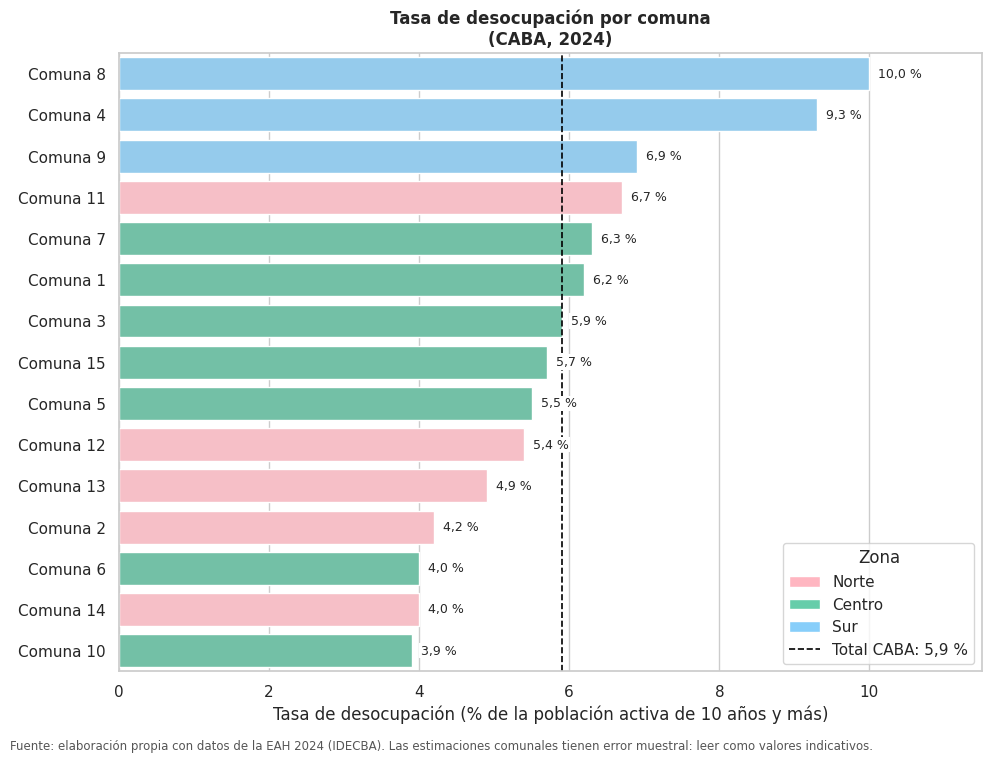

In [ ]:
# ---------------------------------------------------------------------------
# GRÁFICO 2: TASA DE DESOCUPACIÓN POR COMUNA
# ---------------------------------------------------------------------------
fig, ax = barras_por_comuna(
    columna="Tasa_Desocupacion",
    titulo=f"Tasa de desocupación por comuna\n(CABA, {ANIO_GRAFICO})",
    xlabel="Tasa de desocupación (% de la población activa de 10 años y más)",
    total_caba=total_del_anio("Desocupacion_Total_CABA"),
    fmt=fmt_pct,
    nota=f"Fuente: elaboración propia con datos de la EAH {ANIO_GRAFICO} (IDECBA). "
         "Las estimaciones comunales tienen error muestral: leer como valores indicativos.")
plt.savefig("grafico_desocupacion_por_comuna.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# =============================================================================
# ANÁLISIS COMPARATIVO DEL DELITO EN LAS COMUNAS DE CABA (2017-2025)
# Gráficos: (a) Delito vs. Ingreso, (b) Delito vs. Hacinamiento/Desocupación,
#           (c) Ranking de comunas por perfil territorial
# =============================================================================

# ---------------------------------------------------------------------------
# 0. LIBRERÍAS Y CONFIGURACIÓN
# ---------------------------------------------------------------------------
import glob
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns

# Silencia únicamente los avisos internos de openpyxl (no los de seaborn/pandas)
warnings.filterwarnings("ignore", module="openpyxl")
logging.getLogger("openpyxl").setLevel(logging.ERROR)

sns.set_theme(style="whitegrid", context="notebook")


# Las mismas 3 zonas y colores que en la parte de condiciones territoriales
PERFILES = {"Norte": [2, 11, 12, 13, 14],
            "Centro": [1, 3, 5, 6, 7, 10, 15],
            "Sur": [4, 8, 9]}
ORDEN_PERFILES = ["Norte", "Centro", "Sur"]
PALETA = {"Norte": "#FFB6C1", "Centro": "#66CDAA", "Sur": "#87CEFA"}

COMUNAS_ETIQUETADAS = [1, 4, 8, 14]   # comunas rotuladas en los scatter
ANIOS_SOCIO = range(2017, 2026)       # la EAH no se relevó en 2020 (se omite sola)


def formato_miles(x, _pos=None):
    """12345 -> '12.345' (separador de miles con punto, como en Argentina)."""
    return f"{x:,.0f}".replace(",", ".")


def buscar_archivo(patron):
    """Busca un archivo en el directorio actual (Colab: panel de archivos)."""
    hallados = glob.glob(patron)
    if not hallados:
        raise FileNotFoundError(f"No se encontró ningún archivo con el patrón: {patron}")
    return hallados[0]


# ---------------------------------------------------------------------------
# 1. DELITO (SNIC): tasa total anual por comuna
# ---------------------------------------------------------------------------
snic = pd.read_csv("https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/franco-iandoli/Datasets/snic_amba_2017_2025.csv")
snic = snic[
    (snic["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires")
    & (snic["departamento_nombre"].str.startswith("Comuna"))   # excluye "sin determinar"
].copy()

# Serie comparable: solo los tipos de delito presentes en todos los años
# (el SNIC amplía el listado de tipos de delito a partir de 2023)
tipos_por_anio = snic.groupby("anio")["codigo_delito_snic_nombre"].apply(set)
tipos_comunes = set.intersection(*tipos_por_anio.values)
snic = snic[snic["codigo_delito_snic_nombre"].isin(tipos_comunes)]

# Tasa total = suma de las tasas de cada tipo (categorías excluyentes, misma población)
tasa_anual = (snic.groupby(["departamento_nombre", "anio"])["tasa_hechos"]
              .sum().reset_index(name="Tasa_Delito"))
tasa_anual["Comuna"] = tasa_anual["departamento_nombre"].str.extract(r"(\d+)")[0].astype(int)
tasa_anual = tasa_anual.drop(columns="departamento_nombre")

# Promedio 2017-2025 (todos los años): es el que se usa en el ranking del gráfico c
ranking = tasa_anual.groupby("Comuna")["Tasa_Delito"].mean().reset_index()
print(f"Tasa promedio CABA 2017-2025: {ranking['Tasa_Delito'].mean():,.1f} por 100.000 hab.")


# ---------------------------------------------------------------------------
# 2. INDICADORES SOCIOECONÓMICOS (EAH): ingreso, desocupación, hacinamiento
# ---------------------------------------------------------------------------
url_datos = "https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/franco-iandoli/Datasets/"
f_ipcf = url_datos + "MT_eah_2417.xlsx"   # Ingreso per cápita familiar
f_emp = url_datos + "MT_eah_0917.xlsx"    # Mercado de trabajo
f_h04 = url_datos + "H04_co.xlsx"         # Personas por ambiente

def solo_comunas(df, cols):
    """Se queda con las filas de comunas 1-15 (descarta títulos, 'Total' y notas)."""
    num = pd.to_numeric(df[0], errors="coerce")
    out = df[num.between(1, 15)].iloc[:, cols].copy()
    out.columns = ["Comuna"] + list(out.columns[1:])
    return out


def leer_anio(anio):
    hoja = str(anio)

    # --- Ingreso per cápita familiar (IPCF), en pesos corrientes del año ---
    raw = pd.read_excel(f_ipcf, sheet_name=hoja, header=None)
    ipcf_total_caba = pd.to_numeric(
        raw.loc[raw[0].astype(str).str.strip() == "Total", 1].iloc[0])
    ipcf = solo_comunas(raw, [0, 1]); ipcf.columns = ["Comuna", "IPCF"]

    # --- Desocupación (la hoja trae Total / Varones / Mujeres: nos quedamos con el Total) ---
    raw = pd.read_excel(f_emp, sheet_name=hoja, header=None)
    emp = solo_comunas(raw, [0, 3]); emp.columns = ["Comuna", "Desocupacion"]
    emp = emp.drop_duplicates("Comuna", keep="first")

    # --- Hacinamiento: % de hogares con MÁS de 2 personas por ambiente ---
    # = 100 - (hasta 0,99) - (1 a 1,99). Evita las celdas suprimidas ('---') de las
    # categorías pequeñas (CV > 30%), que son las que rompen la suma directa.
    raw = pd.read_excel(f_h04, sheet_name=hoja, header=None)
    hac = solo_comunas(raw, [0, 2, 3]); hac.columns = ["Comuna", "p1", "p2"]
    for c in ("p1", "p2"):
        hac[c] = pd.to_numeric(hac[c], errors="coerce")
    hac["Hacinamiento"] = 100 - hac["p1"] - hac["p2"]

    df = (ipcf.merge(emp, on="Comuna").merge(hac[["Comuna", "Hacinamiento"]], on="Comuna"))
    df = df.apply(pd.to_numeric, errors="coerce").astype(float)   # todo numérico (float)
    df["Comuna"] = df["Comuna"].astype(int)
    # IMPORTANTE: el IPCF está en pesos corrientes y hubo mucha inflación entre 2017 y 2025.
    # Promediar pesos nominales de distintos años no tiene sentido. Se usa un ÍNDICE
    # RELATIVO (promedio de CABA = 100 en cada año), que es comparable entre años.
    df["IPCF_Relativo"] = df["IPCF"] / ipcf_total_caba * 100
    df["anio"] = anio
    return df


socio_anual = []
for a in ANIOS_SOCIO:
    try:
        socio_anual.append(leer_anio(a))
    except ValueError:      # hoja inexistente (p. ej. 2020)
        print(f"Aviso: sin datos EAH para {a}; se omite ese año.")
socio_anual = pd.concat(socio_anual, ignore_index=True)


# ---------------------------------------------------------------------------
# 3. BASE FINAL POR COMUNA (promedio de los años con datos EAH)
# ---------------------------------------------------------------------------
# Para los scatter se usan los MISMOS años en delito y en variables socioeconómicas.
panel = socio_anual.merge(tasa_anual, on=["Comuna", "anio"], how="inner")
VARS = ["Tasa_Delito", "IPCF_Relativo", "Desocupacion", "Hacinamiento"]
base = panel.groupby("Comuna")[VARS].mean().astype(float).reset_index()


def asignar_perfil(c):
    for perfil, comunas in PERFILES.items():
        if c in comunas:
            return perfil
    return "Resto de CABA"


base["Perfil"] = base["Comuna"].apply(asignar_perfil)
ranking["Perfil"] = ranking["Comuna"].apply(asignar_perfil)

print("\nAños usados en los scatter:", sorted(int(a) for a in panel["anio"].unique()))
print(base.round(1).to_string(index=False))

# ---------------------------------------------------------------------------
# 4. FUNCIONES AUXILIARES DE GRAFICACIÓN
# ---------------------------------------------------------------------------
def scatter_con_tendencia(ax, x, xlabel, titulo):
    """Dispersión por perfil + recta de tendencia (mínimos cuadrados) + rótulos."""
    sns.regplot(data=base, x=x, y="Tasa_Delito", scatter=False, ci=None,
                color="#444444", line_kws={"linewidth": 1.8, "linestyle": "--"}, ax=ax)
    sns.scatterplot(data=base, x=x, y="Tasa_Delito", hue="Perfil", hue_order=ORDEN_PERFILES,
                    palette=PALETA, s=130, edgecolor="white", linewidth=0.8,
                    legend=False, ax=ax, zorder=3)
    for _, fila in base[base["Comuna"].isin(COMUNAS_ETIQUETADAS)].iterrows():
        ax.annotate(f"Comuna {int(fila['Comuna'])}", (fila[x], fila["Tasa_Delito"]),
                    xytext=(8, 8), textcoords="offset points", fontsize=10, fontweight="bold")
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Tasa de delito (hechos cada 100.000 hab.)")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(formato_miles))


def leyenda_perfiles(fig_o_ax, **kw):
    handles = [Patch(facecolor=PALETA[p], label=p) for p in ORDEN_PERFILES]
    return fig_o_ax.legend(handles=handles, title="Perfil territorial", frameon=True, **kw)

Tasa promedio CABA 2017-2025: 5,618.5 por 100.000 hab.

Años usados en los scatter: [2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025]
 Comuna  Tasa_Delito  IPCF_Relativo  Desocupacion  Hacinamiento Perfil
      1      10730.0           94.4           7.9          18.7 Centro
      2       5467.5          132.1           4.7           3.8  Norte
      3       7702.2           83.8           6.8          12.0 Centro
      4       7046.6           64.8           9.8          16.6    Sur
      5       4901.1          101.9           5.1           6.4 Centro
      6       4135.5          115.3           4.6           2.9 Centro
      7       5526.3           80.5           7.4           9.3 Centro
      8       5042.6           45.9          11.6          21.7    Sur
      9       6161.1           70.0           6.3           8.5    Sur
     10       4985.1           80.0           6.4           5.9 Centro
     11       4496.8           92.9           6.4           4.4  Norte
     12       4

## Sección 1 · Gráfico (a): Delito vs. Ingreso per cápita familiar

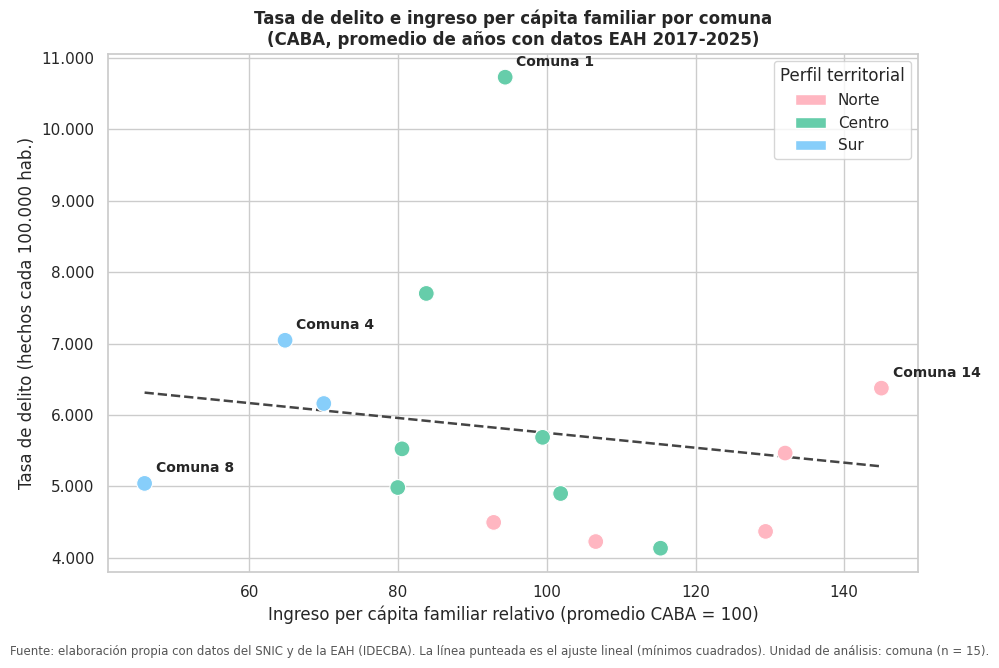

In [ ]:
# ---------------------------------------------------------------------------
# 5. GRÁFICO (a): DELITO vs. INGRESO PER CÁPITA FAMILIAR
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6.5))
scatter_con_tendencia(
    ax, "IPCF_Relativo",
    "Ingreso per cápita familiar relativo (promedio CABA = 100)",
    "Tasa de delito e ingreso per cápita familiar por comuna\n(CABA, promedio de años con datos EAH 2017-2025)")
leyenda_perfiles(ax, loc="upper right")
fig.text(0.01, -0.02, "Fuente: elaboración propia con datos del SNIC y de la EAH (IDECBA). "
         "La línea punteada es el ajuste lineal (mínimos cuadrados). Unidad de análisis: comuna (n = 15).",
         fontsize=8.5, color="#555555")
plt.tight_layout()
plt.savefig("grafico_a_delito_vs_ingreso.png", dpi=300, bbox_inches="tight")
plt.show()

## Sección 2 · Gráfico (b): Delito vs. Hacinamiento y Desocupación

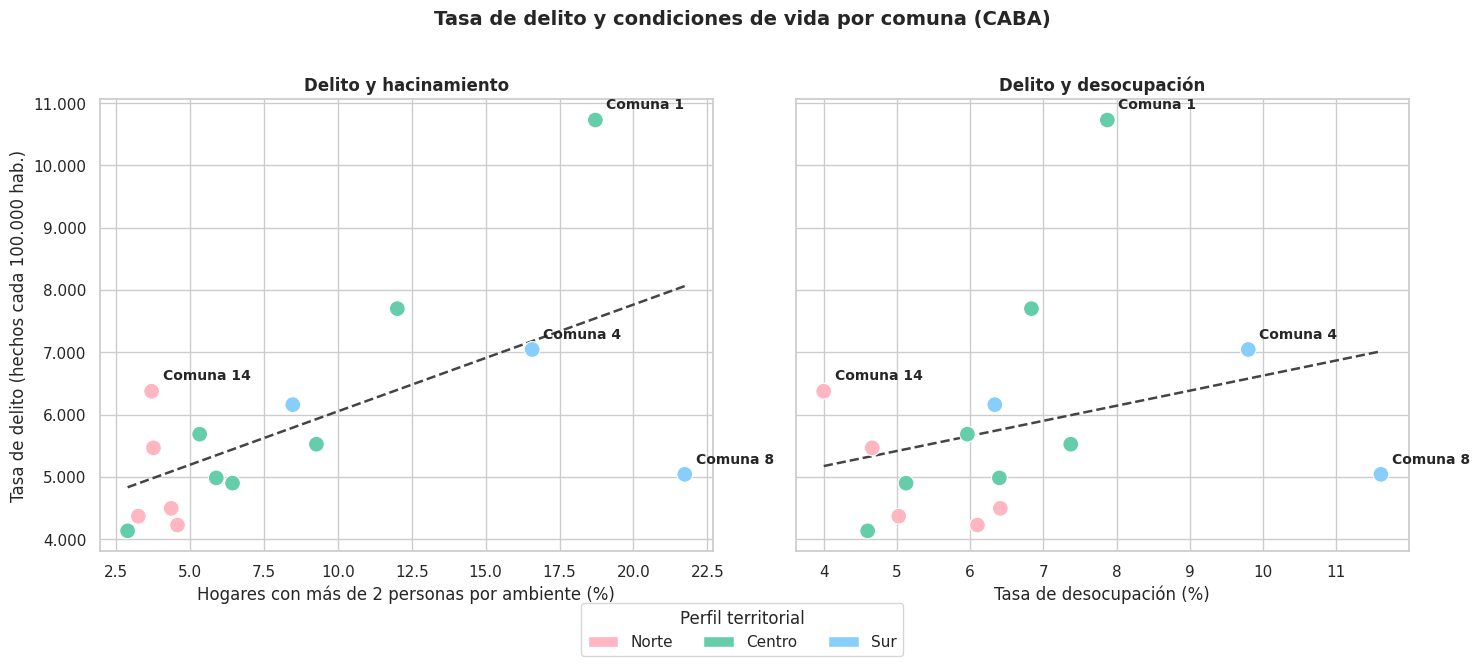

In [ ]:
# ---------------------------------------------------------------------------
# 6. GRÁFICO (b): DELITO vs. HACINAMIENTO Y DESOCUPACIÓN
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
scatter_con_tendencia(axes[0], "Hacinamiento",
                      "Hogares con más de 2 personas por ambiente (%)",
                      "Delito y hacinamiento")
scatter_con_tendencia(axes[1], "Desocupacion",
                      "Tasa de desocupación (%)", "Delito y desocupación")
axes[1].set_ylabel("")
leyenda_perfiles(fig, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Tasa de delito y condiciones de vida por comuna (CABA)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("grafico_b_delito_vs_hacinamiento_desocupacion.png", dpi=300, bbox_inches="tight")
plt.show()

## Sección 3 · Gráfico (c): Ranking de comunas por tasa de delito

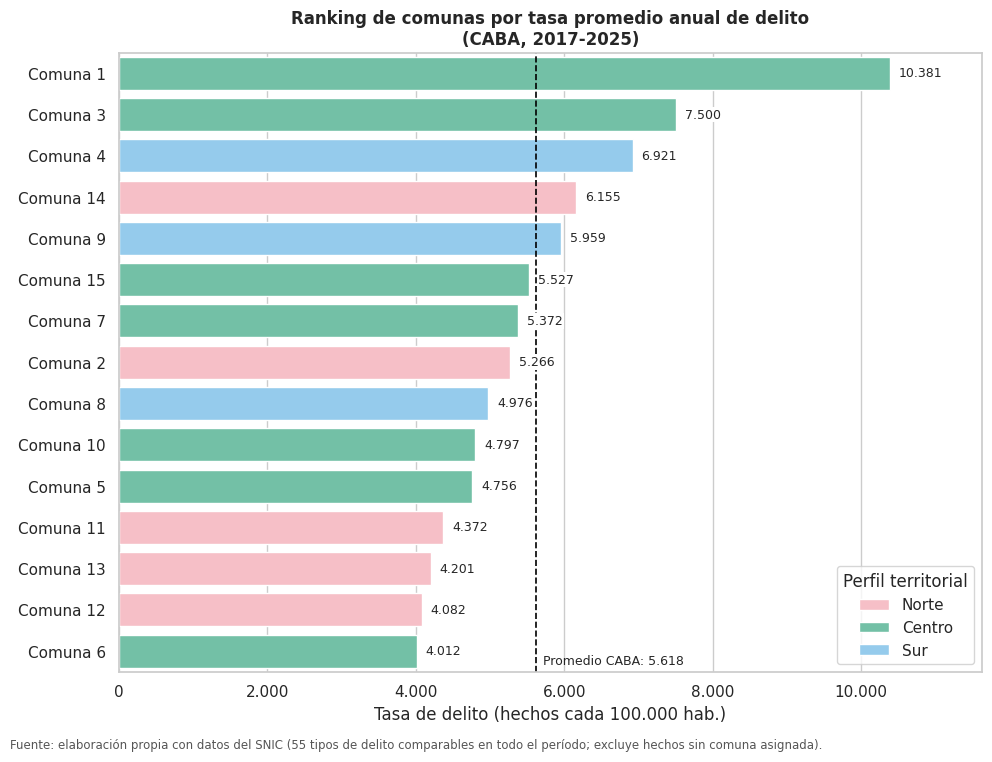

In [ ]:
# ---------------------------------------------------------------------------
# 7. GRÁFICO (c): RANKING DE COMUNAS POR TASA DE DELITO (2017-2025)
# ---------------------------------------------------------------------------
rk = ranking.sort_values("Tasa_Delito", ascending=False).reset_index(drop=True)
rk["Etiqueta"] = "Comuna " + rk["Comuna"].astype(str)
promedio_caba = rk["Tasa_Delito"].mean()

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.barplot(data=rk, y="Etiqueta", x="Tasa_Delito", hue="Perfil", hue_order=ORDEN_PERFILES,
            palette=PALETA, dodge=False, order=rk["Etiqueta"], ax=ax)
for i, v in enumerate(rk["Tasa_Delito"]):                 # valor al final de cada barra
    ax.text(v + 120, i, formato_miles(v), va="center", fontsize=9, zorder=5,
            bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))
ax.axvline(promedio_caba, color="black", linestyle="--", linewidth=1.2)
ax.text(promedio_caba + 100, len(rk) - 0.6, f"Promedio CABA: {formato_miles(promedio_caba)}",
        fontsize=9, va="bottom", zorder=5)
ax.set_title("Ranking de comunas por tasa promedio anual de delito\n(CABA, 2017-2025)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Tasa de delito (hechos cada 100.000 hab.)")
ax.set_ylabel("")
ax.set_xlim(0, rk["Tasa_Delito"].max() * 1.12)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(formato_miles))
ax.legend(title="Perfil territorial", loc="lower right", frameon=True)
fig.text(0.01, -0.01, f"Fuente: elaboración propia con datos del SNIC ({len(tipos_comunes)} tipos de delito "
         "comparables en todo el período; excluye hechos sin comuna asignada).", fontsize=8.5, color="#555555")
plt.tight_layout()
plt.savefig("grafico_c_ranking_comunas.png", dpi=300, bbox_inches="tight")
plt.show()

**Zona Centro (Comunas 1, 3, 5, 6, 7, 10 y 15).** Es la zona más heterogénea. Incluye las dos comunas con las tasas más altas de la Ciudad, la 1 (10.381,2) y la 3 (7.499,8), pero también la más baja, la 6 (4.011,6). Sin las comunas 1 y 3, el promedio de la zona cae de 6.049 a 4.893, por debajo del promedio de CABA. En las comunas 1 y 3, con ingresos algo inferiores al promedio, el delito parece responder más a la oportunidad que a la vulnerabilidad: la concentración de comercios, oficinas, transporte y turismo atrae a muchas personas que no viven allí, lo que aumenta los posibles blancos de delito (hurtos y robos en la vía pública). Como esas personas no se cuentan en la población residente, la tasa de la Comuna 1 está sobreestimada.

**Zona Sur (Comunas 4, 8 y 9).** Concentra las peores condiciones de vida: en 2024, el ingreso per cápita familiar de la Comuna 8 era apenas el 51 % del promedio de la Ciudad, y el de las comunas 4 y 9, el 73 % y el 77 %. También tiene la mayor desocupación (10,0 %, 9,3 % y 6,9 %) y un hacinamiento alto en las comunas 8 (17,9 %) y 4 (15,7 %). Es la zona con la tasa promedio más alta (5.952), pero no es homogénea: la Comuna 4 (6.920,6) y la Comuna 9 (5.959,0) superan el promedio de la Ciudad, mientras que la Comuna 8, la más pobre, queda por debajo (4.976,5). Por eso, la vulnerabilidad no puede leerse como causa directa del nivel de delito. Entre las explicaciones posibles figuran una menor propensión a denunciar, menos blancos de oportunidad y diferencias en el tipo de delito que la tasa total no muestra.

**Zona Norte (Comunas 2, 11, 12, 13 y 14).** Tiene los ingresos más altos (en 2024, las comunas 2, 14 y 13 superaban en un 23 % a 33 % el promedio de la Ciudad), la desocupación más baja y un hacinamiento mínimo. Es la zona con la tasa promedio más baja (4.815), pero tampoco es homogénea: las comunas 11, 12 y 13 están entre las de menor delito, mientras que la Comuna 14 (6.154,8) supera el promedio de la Ciudad. Su posición se explica por Palermo, un polo gastronómico, comercial y turístico. Que un mayor ingreso no siempre implique menos delito confirma que los delitos contra la propiedad también responden a la oportunidad (riqueza expuesta y tránsito de personas), no solo a la privación.

Estos resultados se refieren a comunas, no a personas: no permiten afirmar que los residentes de una comuna con peores condiciones delinquen más o son más victimizados (falacia ecológica). Tampoco demuestran causalidad, porque hay factores que no se miden (población flotante, propensión a denunciar, patrullaje) y el análisis se apoya en solo 15 comunas.000